In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

%matplotlib inline

In [4]:
df = pd.read_csv("../data/clean/merged_data_sets.csv", sep=",", dtype={"Variation": str})

In [5]:
print('-'*10 + 'Review data types of data frame' + '-'*10)
df.dtypes

----------Review data types of data frame----------


Unnamed: 0              int64
client_id               int64
Variation                 str
visitor_id                str
visit_id                  str
process_step              str
date_time                 str
client_tenure_yr      float64
client_tenure_mnth    float64
client_age            float64
gender                    str
num_accts             float64
total_balance         float64
calls_6_mnth          float64
logons_6_mnth         float64
dtype: object

In [6]:
print('-'*10 + 'Drop columns and review new data frame' + '-'*10)
df = df.drop(columns=["Unnamed: 0", "client_tenure_yr", "client_tenure_mnth", "client_age", "gender", "total_balance", "calls_6_mnth"])
df.head()

----------Drop columns and review new data frame----------


,client_id,Variation,visitor_id,visit_id,process_step,date_time,num_accts,logons_6_mnth
0,9988021,Test,580560515_7732621733,781255054_21935453173_531117,step_3,2017-04-17 15:27:07,2.0,4.0
1,9988021,Test,580560515_7732621733,781255054_21935453173_531117,step_2,2017-04-17 15:26:51,2.0,4.0
2,9988021,Test,580560515_7732621733,781255054_21935453173_531117,step_3,2017-04-17 15:19:22,2.0,4.0
3,9988021,Test,580560515_7732621733,781255054_21935453173_531117,step_2,2017-04-17 15:19:13,2.0,4.0
4,9988021,Test,580560515_7732621733,781255054_21935453173_531117,step_3,2017-04-17 15:18:04,2.0,4.0


In [7]:
test_dupes = df[df["Variation"] == "Test"].duplicated().sum()
control_dupes = df[df["Variation"] == "Control"].duplicated().sum()
total_dupes = df.duplicated().sum()

print('-'*10 + 'Analyzing duplicates' + '-'*10)
print(f"The number of duplicates in Test group is: {test_dupes}")
print(f"The number of duplicates in Control group is: {control_dupes}")
print(f"The number of NaN duplicates group is: {total_dupes - test_dupes - control_dupes}")

----------Analyzing duplicates----------
The number of duplicates in Test group is: 1148
The number of duplicates in Control group is: 2926
The number of NaN duplicates group is: 1860


In [9]:
print('-'*10 + 'Examining duplicates' + '-'*10)
display(df[df.duplicated(keep=False)])

----------Examining duplicates----------


,client_id,Variation,visitor_id,visit_id,process_step,date_time,num_accts,logons_6_mnth
97,438567,Test,923318467_50708963627,330543236_29863358529_771432,start,2017-04-28 02:52:29,2.0,9.0
98,438567,Test,923318467_50708963627,330543236_29863358529_771432,start,2017-04-28 02:52:29,2.0,9.0
373,5376894,Test,622509328_44408201172,688984457_43441834354_912755,start,2017-04-28 14:20:01,2.0,9.0
374,5376894,Test,622509328_44408201172,688984457_43441834354_912755,start,2017-04-28 14:20:01,2.0,9.0
380,3751049,Control,937925261_74821699083,628817270_45049432060_475841,start,2017-05-15 23:09:44,2.0,8.0
...,...,...,...,...,...,...,...,...
449563,4553664,NaN,795008403_33653570753,439592710_65772985411_546352,start,2017-04-28 07:07:17,2.0,2.0
449690,1672289,NaN,658797407_91003097342,430110748_90347503221_597628,start,2017-05-01 19:28:53,2.0,2.0
449691,1672289,NaN,658797407_91003097342,430110748_90347503221_597628,start,2017-05-01 19:28:53,2.0,2.0
449792,3897324,NaN,80177429_24869309091,149796456_64325617570_112561,start,2017-05-04 08:21:30,2.0,7.0


In [10]:
print('-'*10 + 'Drop duplicates and create & understand new concise data frame focus on client vs process steps' + '-'*10)
df = df.drop_duplicates()
df_client_steps = df[["client_id", "Variation", "process_step"]]
print(df_client_steps.nunique())
print(df_client_steps["Variation"].value_counts(dropna = False))

----------Drop duplicates and create & understand new concise data frame focus on client vs process steps----------
client_id       70609
Variation           2
process_step        5
dtype: int64
Variation
Test       176699
Control    140536
NaN        126662
Name: count, dtype: int64


In [11]:
print('-'*10 + 'Count unique number of process steps per client_id' + '-'*10)
df_total_steps = df_client_steps.groupby(['client_id', 'Variation'])['process_step'].nunique().reset_index()
display(df_total_steps.head())

----------Count unique number of process steps per client_id----------


,client_id,Variation,process_step
0,555,Test,5
1,647,Test,5
2,934,Test,1
3,1028,Control,4
4,1104,Control,1


In [12]:
df_total_steps.to_csv(
    "customer_unique_steps.csv",
    index=False,
    encoding="utf-8-sig"
)

In [9]:
# Filter into control and test data frames
df_total_steps_control = df_total_steps[df_total_steps["Variation"] == "Control"]
df_total_steps_test = df_total_steps[df_total_steps["Variation"] == "Test"]
print('-'*10 + 'Filter into control data frame and control frame' + '-'*10)
display(df_total_steps_control.head())
print("\n"+'-'*10 + 'Filter into test data frame and control frame' + '-'*10)
display(df_total_steps_test.head())

----------Filter into control data frame and control frame----------


,client_id,Variation,process_step
3,1028,Control,4
4,1104,Control,1
5,1186,Control,3
6,1195,Control,5
7,1197,Control,5



----------Filter into test data frame and control frame----------


,client_id,Variation,process_step
0,555,Test,5
1,647,Test,5
2,934,Test,1
8,1336,Test,5
9,1346,Test,4


----------Distribution of the 5 process steps for control group----------


,process_step,count
1,1,3327
3,2,1489
4,3,1320
2,4,2190
0,5,15206


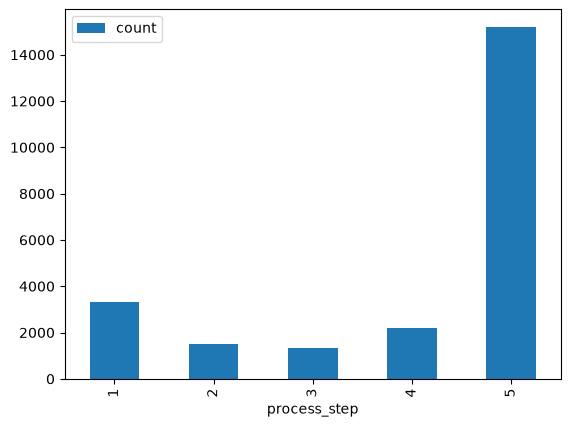

In [10]:
print('-'*10 + 'Distribution of the 5 process steps for control group' + '-'*10)
control_counts = df_total_steps_control["process_step"].value_counts().reset_index()
control_counts = control_counts.sort_values(by="process_step")
control_counts.plot.bar(x="process_step")
display(control_counts)

----------Distribution of the 5 process steps for test group----------


,process_step,count
1,1,2654
3,2,2013
4,3,1450
2,4,2513
0,5,18338


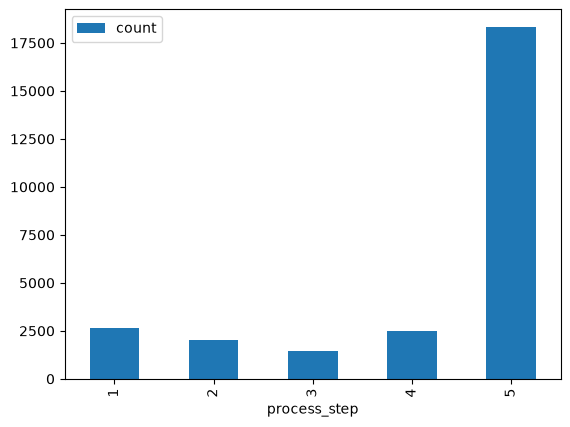

In [11]:
print('-'*10 + 'Distribution of the 5 process steps for test group' + '-'*10)
test_counts = df_total_steps_test["process_step"].value_counts().reset_index()
test_counts = test_counts.sort_values(by="process_step")
test_counts.plot.bar(x="process_step")
display(test_counts)

In [12]:
control_prop = df_total_steps_control["process_step"].value_counts(normalize=True)*100
test_prop = df_total_steps_test["process_step"].value_counts(normalize=True)*100

In [13]:
display(control_prop.reset_index().sort_values(by="process_step"))
display(test_prop.reset_index().sort_values(by="process_step"))

,process_step,proportion
1,1,14.138195
3,2,6.327554
4,3,5.609383
2,4,9.306476
0,5,64.618392


,process_step,proportion
1,1,9.841293
3,2,7.464402
4,3,5.376743
2,4,9.318451
0,5,67.999110


## Chi-Squared Testing

In [14]:
control_vs_test = pd.crosstab(df_total_steps['Variation'], df_total_steps['process_step'])
display(control_vs_test)

process_step,1,2,3,4,5
Variation,,,,,
Control,3327,1489,1320,2190,15206
Test,2654,2013,1450,2513,18338


In [15]:
from scipy.stats import chi2_contingency
chi2_statistic, chi2_p_value, _, expected_freq = chi2_contingency(control_vs_test)

print(chi2_statistic, chi2_p_value, expected_freq)

242.18968189355112 3.132391979694115e-51 [[ 2787.02756436  1631.86265347  1290.76514851  2191.50487129
  15630.83976238]
 [ 3193.97243564  1870.13734653  1479.23485149  2511.49512871
  17913.16023762]]


In [16]:
if chi2_p_value > 0.05:
    print("We keep the null hypothesis")

else:
    print("We reject the null hypothesis");

We reject the null hypothesis


## Chi-Squared Testing Results
p-value < 0.05 therefore null hypothesis is rejected

## Reality of what we would expect for completion is
- **Test Group Actual:**    18338
- **Test Group Expected:**  17913

We exceed test group expected completions by more than 400 completions

## Kramers V

In [17]:
from scipy.stats.contingency import association

# Computing the association between variables in 'crosstab_result' using the "cramer" method
association(control_vs_test, method="cramer")

0.06925196953892947

### Cramér’s V Result
We do see an uplift in the completion rate that is significant but the impact of a 3.4% gain is highly dependent on the size of the existing customer base and the cost of the new design.

In [18]:
df_total_steps["completed"] = df_total_steps["process_step"] == 5
completed_vs_group = pd.crosstab(df_total_steps["Variation"], df_total_steps["completed"])
display(completed_vs_group)

completed,False,True
Variation,,
Control,8326,15206
Test,8630,18338


In [19]:
chi2_statistic, chi2_p_value, _, expected_freq = chi2_contingency(completed_vs_group)
print(chi2_statistic, chi2_p_value)
display(expected_freq)

64.24742935717805 1.097350214599806e-15


array([[ 7901.16023762, 15630.83976238],
       [ 9054.83976238, 17913.16023762]])

In [20]:
association(completed_vs_group, method="cramer")

0.03571030973761421